In [9]:
print("Name:Supriya K \nRoll No:24BAD118")

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

vocab_size = 10000
max_length = 200

(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

print("First review:", x_train[0])
print("First label:", y_train[0])

x_train = pad_sequences(x_train, maxlen=max_length, padding='post')
x_test = pad_sequences(x_test, maxlen=max_length, padding='post')

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

print("Positive reviews:", np.sum(y_train == 1))
print("Negative reviews:", np.sum(y_train == 0))

Name:Supriya K 
Roll No:24BAD118
Training samples: 25000
Testing samples: 25000
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 10

In [8]:
print("Name:Supriya K \nRoll No:24BAD118")

embedding_dim = 128

embedding_layer = Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim,

)

sample_embedding = embedding_layer(x_train[:1])

print("Embedding shape:", sample_embedding.shape)

Name:Supriya K 
Roll No:24BAD118
Embedding shape: (1, 200, 128)


In [7]:
print("Name:Supriya K \nRoll No:24BAD118")

model = Sequential([
    Embedding(vocab_size, embedding_dim),
    LSTM(128),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Name:Supriya K 
Roll No:24BAD118


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Name:Supriya K /nRoll No:24BAD118
Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 149s 477ms/step - accuracy: 0.5796 - loss: 0.6580 - val_accuracy: 0.6180 - val_loss: 0.6508
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 146s 468ms/step - accuracy: 0.6838 - loss: 0.5782 - val_accuracy: 0.7272 - val_loss: 0.5643
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 148s 473ms/step - accuracy: 0.7944 - loss: 0.4745 - val_accuracy: 0.7790 - val_loss: 0.5102
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 201s 470ms/step - accuracy: 0.7806 - loss: 0.4709 - val_accuracy: 0.7754 - val_loss: 0.5252
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 148s 472ms/step - accuracy: 0.8115 - loss: 0.4332 - val_accuracy: 0.7824 - val_loss: 0.5144


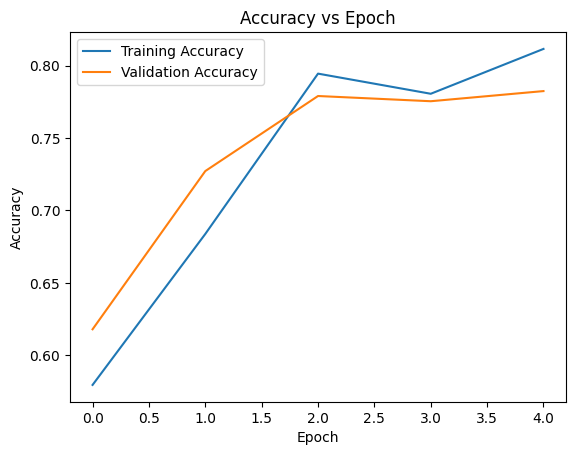

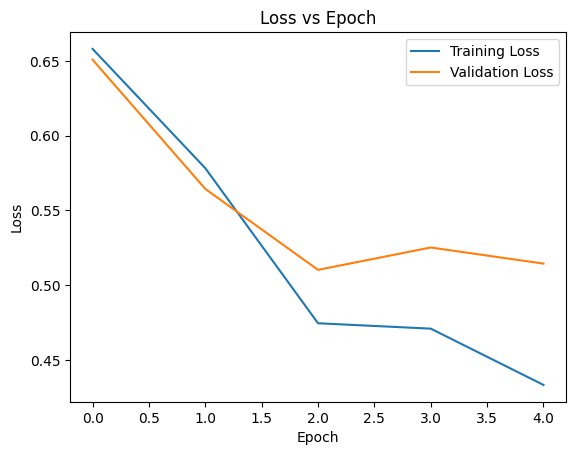

782/782 ━━━━━━━━━━━━━━━━━━━━ 74s 94ms/step - accuracy: 0.7886 - loss: 0.5093
Test Loss: 0.5093387365341187
Test Accuracy: 0.788640022277832
782/782 ━━━━━━━━━━━━━━━━━━━━ 73s 93ms/step
Accuracy: 0.78864
Precision: 0.7789115646258503
Recall: 0.80608
F1-Score: 0.7922629344236515
Confusion Matrix:
[[ 9640  2860]
 [ 2424 10076]]
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Review: This movie was excellent and very enjoyable
Predicted Sentiment: Positive
Score: 0.8067547

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Review: This movie was boring and disappointing
Predicted Sentiment: Negative
Score: 0.26716062



In [6]:
print("Name:Supriya K \nRoll No:24BAD118")

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Epoch')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss vs Epoch')
plt.legend()
plt.show()

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

y_pred_prob = model.predict(x_test)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)
print("Confusion Matrix:")
print(cm)

word_index = imdb.get_word_index()

def encode_review(review):
    words = review.lower().split()
    sequence = []

    for word in words:
        index = word_index.get(word, 2)
        sequence.append(index + 3)

    return pad_sequences([sequence], maxlen=max_length, padding='post')

reviews = [
    "This movie was excellent and very enjoyable",
    "This movie was boring and disappointing"
]

for review in reviews:
    encoded_review = encode_review(review)
    prediction = model.predict(encoded_review)[0][0]

    if prediction >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Score:", prediction)
    print()